# **ML Assignment 2: Text Data**

**Dataset:** [Food Delivery Apps Reviews](https://www.kaggle.com/datasets/skamlo/food-delivery-apps-reviews)

In [ ]:
# Set EXTRACT_FEATURE = True on first run to extract TF-IDF, SVD, and BERT features (takes ~5-10 min on Colab GPU)
# Once saved in ./features/, you can set EXTRACT_FEATURE = False to reuse them.
EXTRACT_FEATURE = True
TRAIN_MODEL = True

# Ignore columns that rarely appear / are mostly missing (e.g., replyContent, repliedDate)
MIN_NON_NULL_RATIO = 0.50  # drop any column with < 50% non-null values

# 1. Download and Import Data

In [ ]:
!pip install -q kagglehub transformers nltk xgboost wordcloud
import os
import glob
import kagglehub

# Download latest version via kagglehub (Google Colab standard way)
path = kagglehub.dataset_download("skamlo/food-delivery-apps-reviews")
print("Path to dataset files:", path)
csv_files = sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
print("CSV files found:", csv_files)

Using Colab cache for faster access to the 'food-delivery-apps-reviews' dataset.
Path to dataset files: /kaggle/input/food-delivery-apps-reviews
CSV files found: ['/kaggle/input/food-delivery-apps-reviews/food_delivery_apps.csv']


In [ ]:
import numpy as np
import pandas as pd

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {path}")

# Load all CSV files (handles both single-file and multi-file archives cleanly)
dfs = [pd.read_csv(f, low_memory=False) for f in csv_files]
df_raw = pd.concat(dfs, ignore_index=True) if len(dfs) > 1 else dfs[0]

# Inspect non-null coverage of every column and drop sparse / rarely populated columns
non_null_ratio = df_raw.notna().mean()
col_coverage = pd.DataFrame({
    "non_null_count": df_raw.notna().sum(),
    "non_null_pct": (non_null_ratio * 100).round(2)
})
print("Column coverage before filtering:")
print(col_coverage)

rare_cols = non_null_ratio[non_null_ratio < MIN_NON_NULL_RATIO].index.tolist()
print(f"\nIgnoring sparse/rarely populated columns (< {int(MIN_NON_NULL_RATIO * 100)}% non-null): {rare_cols}")
df = df_raw.drop(columns=rare_cols).copy()

# Detect text and rating columns cleanly (defaults: 'content' and 'score')
text_col = next((c for c in ["content", "review", "text", "Review", "Content"] if c in df.columns), None)
score_col = next((c for c in ["score", "rating", "stars", "Score", "Rating"] if c in df.columns), None)
if text_col is None or score_col is None:
    raise ValueError(f"Could not locate text/score columns in {list(df.columns)}")

df = df.rename(columns={text_col: "text", score_col: "score"})

# Clean missing / empty reviews and keep valid 1-5 star ratings
df["score"] = pd.to_numeric(df["score"], errors="coerce")
df = df.dropna(subset=["text", "score"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 0].copy()
df["score"] = df["score"].astype(int)
df = df[df["score"].isin([1, 2, 3, 4, 5])].copy()

# 5-class multiclass target: 0..4 corresponding to 1..5 stars
df["target"] = df["score"] - 1
LABEL_NAMES = {0: "1 star", 1: "2 stars", 2: "3 stars", 3: "4 stars", 4: "5 stars"}
NUM_CLASSES = 5

print(f"\nLoaded cleaned dataset: shape={df.shape}, NUM_CLASSES={NUM_CLASSES}")
df.head()

Column coverage before filtering:
              non_null_count  non_null_pct
date                 1247061        100.00
content              1247061        100.00
score                1247061        100.00
userName             1247061        100.00
app                  1247061        100.00
platform             1247061        100.00
replyContent          203760         16.34
repliedDate           203760         16.34
appVersion            973010         78.02

Ignoring sparse/rarely populated columns (< 50% non-null): ['replyContent', 'repliedDate']

Loaded cleaned dataset: shape=(1247061, 8), NUM_CLASSES=5


,date,text,score,userName,app,platform,appVersion,target
0,2022-10-20 17:08:18,"Being single and traveling a lot for work, all...",5,TBeck-NARC,Bolt Food,App Store,NaN,4
1,2022-08-19 15:56:51,App is well-designed and nice to use. Only com...,4,henhouse,Bolt Food,App Store,NaN,3
2,2023-07-26 09:03:32,I’ve had this payment issue for over a month n...,1,hsghdoenvskrbbd,Bolt Food,App Store,NaN,0
3,2022-11-22 10:00:43,Live activities would be nice instead of getti...,4,Sussy31,Bolt Food,App Store,NaN,3
4,2023-06-14 09:04:39,After waiting for over an hour for our food an...,1,schalas1985,Bolt Food,App Store,NaN,0


# 2. EDA (Exploratory Data Analysis)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1247061 entries, 0 to 1247060
Data columns (total 8 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   date        1247061 non-null  object
 1   text        1247061 non-null  object
 2   score       1247061 non-null  int64 
 3   userName    1247061 non-null  object
 4   app         1247061 non-null  object
 5   platform    1247061 non-null  object
 6   appVersion  973010 non-null   object
 7   target      1247061 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 76.1+ MB


## Class distribution

,count
target,
1 star,386150
2 stars,49446
3 stars,58431
4 stars,117580
5 stars,635454


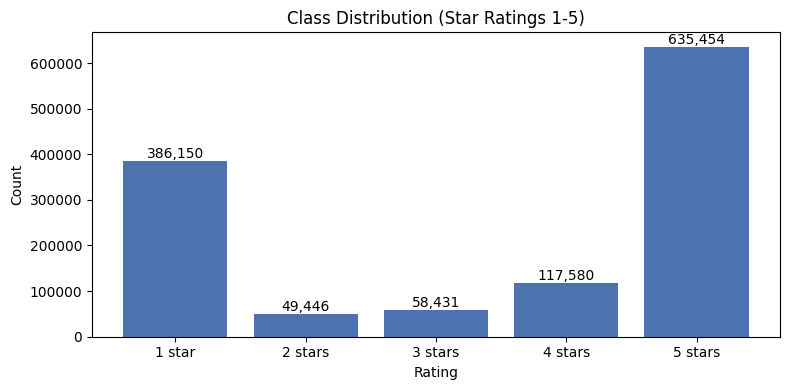


Distribution by app:


,count
app,
Uber Eats,962166
Grubhub,209784
Glovo,47758
Wolt,18458
Bolt Food,8895



Distribution by platform:


,count
platform,
Google Play,1146101
App Store,100960


In [ ]:
import matplotlib.pyplot as plt

class_counts = df["target"].value_counts().sort_index()
display(class_counts.rename(index=LABEL_NAMES))

plt.figure(figsize=(8, 4))
bars = plt.bar([LABEL_NAMES[i] for i in class_counts.index], class_counts.values, color="#4C72B0")
plt.title("Class Distribution (Star Ratings 1-5)")
plt.xlabel("Rating")
plt.ylabel("Count")
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., h, f"{int(h):,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Show distribution by app / platform if present (non-sparse metadata columns)
for meta_col in ["app", "platform"]:
    if meta_col in df.columns:
        print(f"\nDistribution by {meta_col}:")
        display(df[meta_col].value_counts())

**Note:**
- Rarely populated columns (such as `replyContent`, `repliedDate`, and any column with <50% non-null values) are automatically ignored.
- User reviews for food delivery apps are naturally skewed toward extreme ratings (1-star and 5-star reviews), so we use stratified splitting and evaluate **Accuracy**, **Macro F1-score**, and **Weighted F1-score** across all 5 rating classes.

## Distribution of text length
1. by number of words
2. by number of characters

In [ ]:
df["word_count"] = df["text"].apply(lambda x: len(x.split()))
df["char_count"] = df["text"].apply(len)

In [ ]:
# Distribution by number of words
df["word_count"].describe()

,word_count
count,1.247061e+06
mean,1.964482e+01
std,2.713156e+01
min,1.000000e+00
25%,3.000000e+00
50%,9.000000e+00
75%,2.500000e+01
max,9.520000e+02


In [ ]:
df["word_count"].value_counts().sort_index().head(40)

,count
word_count,
1,160604
2,132400
3,78836
4,66247
5,56976
6,47592
7,40045
8,35940
9,31936


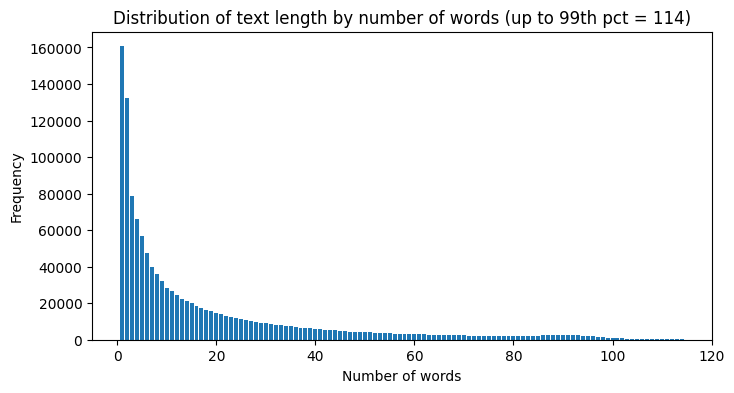

In [ ]:
p99_words = int(df["word_count"].quantile(0.99))
word_count_dist = df[df["word_count"] <= p99_words]["word_count"].value_counts().sort_index()
plt.figure(figsize=(8, 4))
plt.bar(word_count_dist.index, word_count_dist.values)
plt.title(f"Distribution of text length by number of words (up to 99th pct = {p99_words})")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Distribution by number of characters
df["char_count"].describe()

,char_count
count,1.247061e+06
mean,1.056758e+02
std,1.449624e+02
min,1.000000e+00
25%,1.500000e+01
50%,4.700000e+01
75%,1.360000e+02
max,5.116000e+03


Number of bins: 277


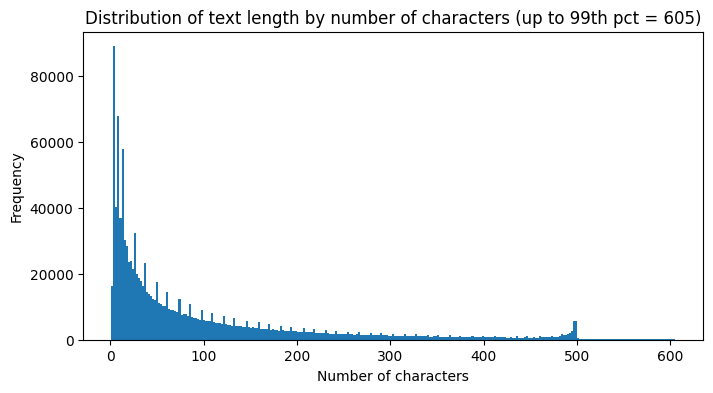

In [ ]:
p99_chars = int(df["char_count"].quantile(0.99))
plt.figure(figsize=(8, 4))
_, bin_edge, _ = plt.hist(df[df["char_count"] <= p99_chars]["char_count"], bins="auto")
print(f"Number of bins: {len(bin_edge) - 1}")
plt.title(f"Distribution of text length by number of characters (up to 99th pct = {p99_chars})")
plt.xlabel("Number of characters")
plt.ylabel("Frequency")
plt.show()

## Word frequency
Before preprocessing result

In [ ]:
from collections import Counter

all_words = " ".join(df["text"]).lower().split()
word_freq = Counter(all_words)
word_freq_df = pd.DataFrame(word_freq.items(), columns=["word", "freq"])
word_freq_df = word_freq_df.sort_values(by="freq", ascending=False)
word_freq_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 413547 entries, 10 to 197208
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   word    413547 non-null  object
 1   freq    413547 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 9.5+ MB


In [ ]:
# top 20 most frequent words
word_freq_df.head(20)

,word,freq
10,the,859746
55,to,717877
2,and,675555
13,i,663585
4,a,403417
97,my,336514
120,it,315870
28,is,315422
6,for,275637
57,app,273762


## Word cloud

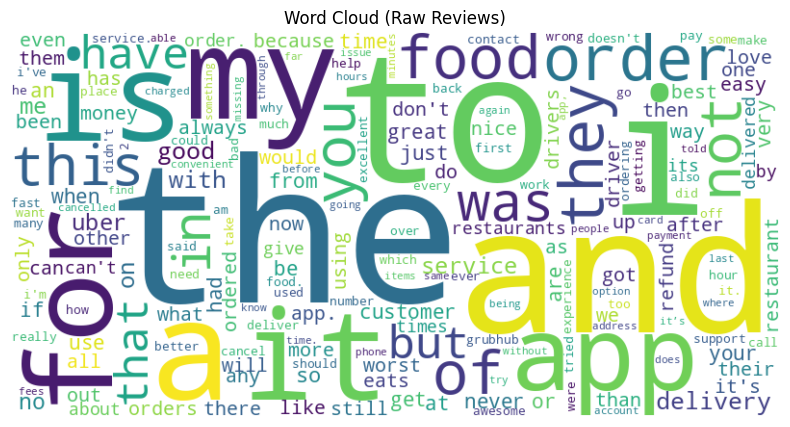

In [ ]:
from wordcloud import WordCloud

wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(word_freq)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud (Raw Reviews)")
plt.show()

# 3. Preprocessing

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

stop_words = set(stopwords.words('english')) - {"no", "not", "never"}
lemmatizer = WordNetLemmatizer()

Preprocess configurations:
* `lowercase`: Turn every alphabetical character to lowercase
* `link`: Remove URLs (`www.example.com`) from text.
* `user`: Remove usernames (`@user123`) from text.
* `special_char`: Remove special characters (comma, period, question mark, emojis, digits, etc.)
* `stopword`: Remove English stopwords while keeping key negations (`no`, `not`, `never`).
* `lemmatize`: Convert words to their base dictionary form (`delivering` -> `deliver`, `orders` -> `order`).

In [ ]:
from sklearn.model_selection import train_test_split

def clean_text(text, lowercase=True, link=True, user=True, special_char=True, stopword=True, lemmatize=True):
    text = str(text)
    if lowercase:
        text = text.lower()
    if link:
        text = re.sub(r"http\S+|www\S+", "", text)
    if user:
        text = re.sub(r"@\w+", "", text)
    if special_char:
        text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()
    if stopword:
        words = [word for word in words if word not in stop_words]
    if lemmatize:
        words = [lemmatizer.lemmatize(word) for word in words]
    return " ".join(words)


def preprocess(df_in, lowercase=True, link=True, user=True, special_char=True, stopword=True, lemmatize=True):
    cleaned = df_in["text"].apply(
        clean_text,
        args=(lowercase, link, user, special_char, stopword, lemmatize)
    )
    y = df_in["target"].astype("int64")
    return train_test_split(cleaned, y, test_size=0.25, stratify=y, random_state=42)

# 4. Extract feature vector

Cap the dataset at `100,000` stratified samples if it exceeds 100k rows so TF-IDF, SVD, and BERT feature extraction stay fast on Colab.

In [ ]:
TOTAL_SAMPLE_SIZE = 100_000

# Keep only the essential columns (text and target), ignoring all other metadata columns
df_model = df[["text", "target"]].copy()

if len(df_model) > TOTAL_SAMPLE_SIZE:
    df_small, _ = train_test_split(
        df_model,
        train_size=TOTAL_SAMPLE_SIZE,
        stratify=df_model["target"],
        random_state=42
    )
else:
    df_small = df_model.copy()

print("Working dataset size:", len(df_small))

Working dataset size: 100000


In [ ]:
df_small["target"].value_counts().sort_index().rename(index=LABEL_NAMES)

,count
target,
1 star,30965
2 stars,3965
3 stars,4685
4 stars,9429
5 stars,50956


To simplify and reduce training time, we use 2 preprocess configs: remove stopwords (`processed_0`, for TF-IDF/SVD) vs keep stopwords (`processed_1`, for BERT).

In [ ]:
processed_0 = preprocess(
    df_small,
    lowercase=True,
    link=True,
    user=True,
    special_char=True,
    stopword=True,   # remove stop words (for TF-IDF & SVD)
    lemmatize=True
)

processed_1 = preprocess(
    df_small,
    lowercase=True,
    link=True,
    user=True,
    special_char=True,
    stopword=False,  # keep stop words (for BERT)
    lemmatize=True
)
print("Train size:", len(processed_0[0]), "| Test size:", len(processed_0[1]))

Train size: 75000 | Test size: 25000


We use 2 methods to extract feature vectors from the text:
1. TF-IDF (max_features = 2500 & 5000, with optional TruncatedSVD to 300 dims)
2. BERT (`bert-base-uncased` mean-pooled token embeddings)

In [ ]:
os.makedirs("./features", exist_ok=True)

In [ ]:
# TF-IDF (no stopwords) + TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from scipy import sparse

if EXTRACT_FEATURE:
    X_train, X_test, y_train, y_test = processed_0
    for num_features in [2500, 5000]:
        vectorizer = TfidfVectorizer(max_features=num_features, ngram_range=(1, 2))
        X_train_tfidf = vectorizer.fit_transform(X_train)
        X_test_tfidf = vectorizer.transform(X_test)
        sparse.save_npz(f"./features/X_train_tfidf_{num_features}.npz", X_train_tfidf)
        sparse.save_npz(f"./features/X_test_tfidf_{num_features}.npz", X_test_tfidf)

        n_comp = min(300, X_train_tfidf.shape[1] - 1)
        svd_model = TruncatedSVD(n_components=n_comp, random_state=42)
        X_train_svd = svd_model.fit_transform(X_train_tfidf).astype(np.float32)
        X_test_svd = svd_model.transform(X_test_tfidf).astype(np.float32)

        print(f"TF-IDF {num_features}: train={X_train_tfidf.shape}, test={X_test_tfidf.shape}")
        print(f"SVD    {num_features}: train={X_train_svd.shape}, test={X_test_svd.shape}")

        np.save(f"./features/X_train_svd_{num_features}.npy", X_train_svd)
        np.save(f"./features/X_test_svd_{num_features}.npy", X_test_svd)
else:
    print("TF-IDF / SVD extraction skipped.")

TF-IDF 2500: train=(75000, 2500), test=(25000, 2500)
SVD    2500: train=(75000, 300), test=(25000, 300)
TF-IDF 5000: train=(75000, 5000), test=(25000, 5000)
SVD    5000: train=(75000, 300), test=(25000, 300)


In [ ]:
# BERT
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using PyTorch device:", device)

if EXTRACT_FEATURE:
    model_name = "bert-base-uncased"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    bert_model = AutoModel.from_pretrained(model_name)
    bert_model.to(device)
    bert_model.eval()

Using PyTorch device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
import math

if EXTRACT_FEATURE:
    BERT_BATCH_SIZE = 128
    MAX_LEN = 128
    print("Extracting BERT embeddings...")
    X_train_b, X_test_b, _, _ = processed_1

    def encode_bert(text_series):
        texts = list(text_series)
        num_batches = math.ceil(len(texts) / BERT_BATCH_SIZE)
        embeds = []
        print(f"Number of batches: {num_batches}")
        for batch in range(num_batches):
            start_idx = batch * BERT_BATCH_SIZE
            end_idx = min(len(texts), (batch + 1) * BERT_BATCH_SIZE)

            inputs = tokenizer(
                texts[start_idx:end_idx],
                padding=True,
                truncation=True,
                max_length=MAX_LEN,
                return_tensors="pt"
            ).to(device)

            with torch.no_grad():
                if device.type == "cuda":
                    with torch.cuda.amp.autocast():
                        outputs = bert_model(**inputs)
                else:
                    outputs = bert_model(**inputs)

            attention_mask = inputs.attention_mask.unsqueeze(-1).float()
            token_sum = (outputs.last_hidden_state.float() * attention_mask).sum(dim=1)
            mask_sum = attention_mask.sum(dim=1).clamp(min=1e-9)
            mean_embeddings = token_sum / mask_sum

            embeds.append(mean_embeddings.cpu().numpy().astype(np.float32))
            if (batch + 1) % 25 == 0 or batch == num_batches - 1:
                print(".", end="", flush=True)
        print()
        return np.concatenate(embeds, axis=0)

    train_embeds = encode_bert(X_train_b)
    np.save("./features/X_train_bert.npy", train_embeds)
    print("X_train_bert shape:", train_embeds.shape)

    test_embeds = encode_bert(X_test_b)
    np.save("./features/X_test_bert.npy", test_embeds)
    print("X_test_bert shape:", test_embeds.shape)
else:
    print("BERT extraction skipped.")

Extracting BERT embeddings...
Number of batches: 586


/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


.

/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


.

/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/29968

... (57 outputs left out)

/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


.

/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_1368/2996801759.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


.
X_test_bert shape: (25000, 768)


In [ ]:
if not EXTRACT_FEATURE:
    if os.path.exists("./features/X_train_bert.npy") and os.path.exists("./features/X_train_tfidf_2500.npz"):
        print("Using existing pre-extracted features in ./features/")
    elif os.path.exists("ML_Assig2_FoodReviews_Features.zip"):
        import zipfile
        with zipfile.ZipFile("ML_Assig2_FoodReviews_Features.zip", "r") as zf:
            zf.extractall("./features")
        print("Extracted ML_Assig2_FoodReviews_Features.zip into ./features")
    else:
        raise FileNotFoundError(
            "Pre-extracted features not found in ./features/. Set EXTRACT_FEATURE = True to extract them first."
        )

# 5. Modeling
There are 3 base feature extraction configurations: TF-IDF (`max_features` 2500 and 5000, without stopwords) and BERT (with stopwords), plus TruncatedSVD (`n_components = 300`) applied to both TF-IDF matrices — a total of **5 feature extraction configurations**:

| Configuration | File Names | Processing | Feature Extraction |
| :--- | :--- | :--- | :--- |
| 1 | `X_train_tfidf_2500.npz`, `X_test_tfidf_2500.npz` | `processed_0` (no stop words) | TF-IDF (`max_features = 2500`) |
| 2 | `X_train_tfidf_5000.npz`, `X_test_tfidf_5000.npz` | `processed_0` (no stop words) | TF-IDF (`max_features = 5000`) |
| 3 | `X_train_svd_2500.npy`, `X_test_svd_2500.npy` | `processed_0` (no stop words) | TF-IDF (2500) + SVD (300) |
| 4 | `X_train_svd_5000.npy`, `X_test_svd_5000.npy` | `processed_0` (no stop words) | TF-IDF (5000) + SVD (300) |
| 5 | `X_train_bert.npy`, `X_test_bert.npy` | `processed_1` (keep stop words) | BERT (`bert-base-uncased`) |

In [ ]:
from scipy import sparse

feature_path = "./features"

_, _, y_train, y_test = processed_0
y_train = np.asarray(y_train, dtype=np.int64)
y_test = np.asarray(y_test, dtype=np.int64)

processed_data = []
for preprocessing_type in ["tfidf_2500", "tfidf_5000"]:
    X_train = sparse.load_npz(f"{feature_path}/X_train_{preprocessing_type}.npz")
    X_test = sparse.load_npz(f"{feature_path}/X_test_{preprocessing_type}.npz")
    processed_data.append((preprocessing_type, X_train, X_test))

for preprocessing_type in ["svd_2500", "svd_5000", "bert"]:
    X_train = np.load(f"{feature_path}/X_train_{preprocessing_type}.npy")
    X_test = np.load(f"{feature_path}/X_test_{preprocessing_type}.npy")
    processed_data.append((preprocessing_type, X_train, X_test))

for name, xt, xte in processed_data:
    print(f"Loaded {name:10s}: train={xt.shape}, test={xte.shape}")

Loaded tfidf_2500: train=(75000, 2500), test=(25000, 2500)
Loaded tfidf_5000: train=(75000, 5000), test=(25000, 5000)
Loaded svd_2500  : train=(75000, 300), test=(25000, 300)
Loaded svd_5000  : train=(75000, 300), test=(25000, 300)
Loaded bert      : train=(75000, 768), test=(25000, 768)


## Overall
**Models to use (30 total configurations):**

- **Linear Models** (`C = {0.5, 1, 2}`) on `tfidf_2500`, `tfidf_5000`, and `bert` (no SVD):
  1. `LogisticRegression` (3 × 3 = 9 models)
  2. `LinearSVC` (3 × 3 = 9 models)
- **Tree-based Models** (`n_estimators = {50, 100}`):
  3. `RandomForestClassifier` on `svd_2500` and `svd_5000` (2 × 2 = 4 models)
  4. `XGBClassifier` on `svd_2500`, `svd_5000`, and `bert` (3 × 2 = 6 models)
- **Deep Learning (PyTorch MLP)** with Dropout + StepLR + Early Stopping:
  5. `MLP` for `bert` — hidden layers `[256, 32]` (1 model)
  6. `MLP` for `svd_5000` — hidden layers `[128, 32]` (1 model)

## Traditional model

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

logistic_config = [{"C": c, "random_state": 42, "max_iter": 1000} for c in [0.5, 1, 2]]
linearsvc_config = [{"C": c, "random_state": 42, "max_iter": 2000} for c in [0.5, 1, 2]]
forest_config = [{"n_estimators": n, "random_state": 42, "n_jobs": -1} for n in [50, 100]]
boost_config = [
    {
        "n_estimators": n,
        "objective": "multi:softprob",
        "num_class": NUM_CLASSES,
        "tree_method": "hist",
        "eval_metric": "mlogloss",
        "n_jobs": -1,
        "random_state": 42
    }
    for n in [50, 100]
]

models = {
    "Logistic Regression": (LogisticRegression, logistic_config),
    "Linear SVC": (LinearSVC, linearsvc_config),
    "Random Forest": (RandomForestClassifier, forest_config),
    "XGBoost": (XGBClassifier, boost_config),
}

In [ ]:
import time

model_result = pd.DataFrame(columns=[
    "classifier",
    "model_config",
    "preprocessing",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "f1_weighted"
])

if TRAIN_MODEL:
    for name, (classifier, model_configs) in models.items():
        print(f"Training {name}")
        start_time = time.time()

        for model_config in model_configs:
            for processing_type, X_train, X_test in processed_data:
                if (name == "Logistic Regression" or name == "Linear SVC") and ("svd" in processing_type):
                    continue
                elif (name == "Random Forest" or name == "XGBoost") and ("tfidf" in processing_type):
                    continue
                elif (name == "Random Forest" and "bert" in processing_type):
                    continue

                model = classifier(**model_config)
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)

                accuracy = accuracy_score(y_test, y_pred)
                precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
                recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
                f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
                f1_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)

                model_result.loc[len(model_result)] = [
                    name,
                    list(model_config.values())[0],
                    processing_type,
                    accuracy, precision, recall, f1, f1_w
                ]

                print(".", end="", flush=True)

        training_time = int(time.time() - start_time)
        print(f" Done training in {training_time // 60} minutes, {training_time % 60} seconds\n")
else:
    print("Training skipped.")

Training Logistic Regression
......... Done training in 9 minutes, 59 seconds

Training Linear SVC
......... Done training in 23 minutes, 21 seconds

Training Random Forest
.... Done training in 8 minutes, 56 seconds

Training XGBoost
...... Done training in 11 minutes, 39 seconds



## Deep learning model

### Configuration

In [ ]:
out_features = NUM_CLASSES
p_drop_out = 0.1
max_epochs = 75
batch_size = 64

tolerance = 1e-5
patience = 5

### Model Architecture

In [ ]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

class MLP(nn.Module):
    def __init__(self, feature_name, in_features, out_features=5, p_drop_out=0.1):
        super().__init__()
        if feature_name == "bert":
            self.stack_layers = nn.Sequential(
                nn.Linear(in_features, 256),
                nn.ReLU(),
                nn.Dropout(p=p_drop_out),
                nn.Linear(256, 32),
                nn.ReLU(),
                nn.Dropout(p=p_drop_out),
                nn.Linear(32, out_features)
            )
        elif feature_name == "svd":
            self.stack_layers = nn.Sequential(
                nn.Linear(in_features, 128),
                nn.ReLU(),
                nn.Dropout(p=p_drop_out),
                nn.Linear(128, 32),
                nn.ReLU(),
                nn.Dropout(p=p_drop_out),
                nn.Linear(32, out_features)
            )
        else:
            raise ValueError("feature_name must be 'bert' or 'svd'")

    def forward(self, x):
        return self.stack_layers(x)

In [ ]:
class FoodReviewsDataset(Dataset):
    def __init__(self, X, y):
        super().__init__()
        self.X = np.asarray(X, dtype=np.float32)
        self.y = np.asarray(y, dtype=np.int64)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        X_i = torch.from_numpy(self.X[i])
        y_i = torch.tensor(self.y[i], dtype=torch.long)
        return X_i, y_i

In [ ]:
def train(model, dataloader, loss_fn, optimizer):
    model.train()
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


def test(model, dataloader, loss_fn, verbose=True):
    model.eval()
    test_loss, correct = 0.0, 0
    num_batch = len(dataloader)
    data_size = len(dataloader.dataset)
    preds_all = []

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            pred_class = pred.argmax(dim=1)
            correct += (pred_class == y).sum().item()
            preds_all.append(pred_class.cpu().numpy())

    test_loss /= num_batch
    correct /= data_size
    if verbose:
        print(f"Val Accuracy: {(100 * correct):>0.1f}%, Loss: {test_loss:>8f}")
    return test_loss, correct, np.concatenate(preds_all)

### Loss and Optimization Configuration

In [ ]:
_, bert_X_train, bert_X_test = processed_data[-1]
_, svd_5000_X_train, svd_5000_X_test = processed_data[-2]

print("svd_5000_X_train.shape", svd_5000_X_train.shape)
print("svd_5000_X_test.shape", svd_5000_X_test.shape)
print("bert_X_train.shape", bert_X_train.shape)
print("bert_X_test.shape", bert_X_test.shape)

svd_5000_X_train.shape (75000, 300)
svd_5000_X_test.shape (25000, 300)
bert_X_train.shape (75000, 768)
bert_X_test.shape (25000, 768)


Training MLP...

--- Training MLP on bert features ---
Early stopping at epoch 22 | best val loss=0.649700, val acc=78.59%
Test bert MLP -> acc=0.7876, f1(macro)=0.4303, f1_weighted=0.7437


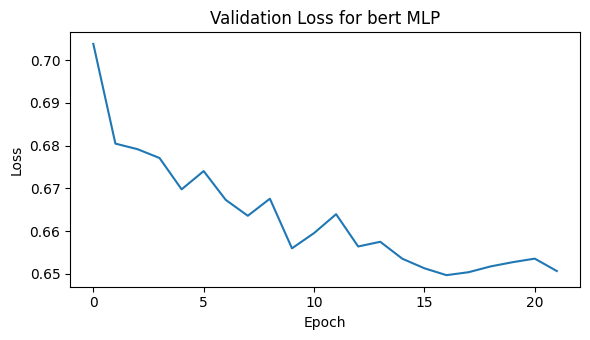


--- Training MLP on svd features ---
Early stopping at epoch 51 | best val loss=0.692103, val acc=76.97%
Test svd MLP -> acc=0.7710, f1(macro)=0.3765, f1_weighted=0.7126


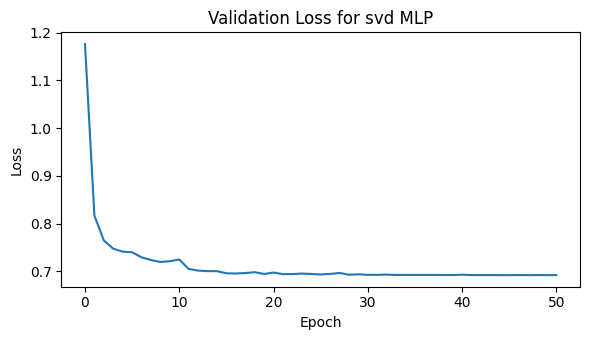

MLP Training finished in 2 minutes, 57 seconds



In [ ]:
if TRAIN_MODEL:
    print("Training MLP...")
    start_time = time.time()

    for feature_name, X_original_train, X_test_arr in [
        ("bert", bert_X_train, bert_X_test),
        ("svd", svd_5000_X_train, svd_5000_X_test)
    ]:
        print(f"\n--- Training MLP on {feature_name} features ---")
        X_tr, X_val, y_tr, y_val = train_test_split(
            X_original_train, y_train, test_size=0.2, random_state=42, stratify=y_train
        )

        train_set = FoodReviewsDataset(X_tr, y_tr)
        validation_set = FoodReviewsDataset(X_val, y_val)
        test_set = FoodReviewsDataset(X_test_arr, y_test)

        train_dataloader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
        validation_dataloader = DataLoader(validation_set, batch_size=batch_size, shuffle=False)
        test_dataloader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

        torch.manual_seed(42)
        model = MLP(feature_name, X_tr.shape[1], out_features=out_features, p_drop_out=p_drop_out).to(device)
        loss_fn = nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(model.parameters(), lr=5e-3, momentum=0.9, weight_decay=1e-5)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.2)

        loss_list = []
        best_loss = float("inf")
        num_patience = 0
        best_accuracy = 0.0
        ckpt_path = f"./features/{feature_name}_mlp.pth"

        for epoch in range(max_epochs):
            train(model, train_dataloader, loss_fn, optimizer)
            val_loss, val_acc, _ = test(model, validation_dataloader, loss_fn, verbose=False)

            loss_list.append(val_loss)
            scheduler.step()

            if val_loss < best_loss - tolerance:
                best_loss = val_loss
                best_accuracy = val_acc
                torch.save(model.state_dict(), ckpt_path)
                num_patience = 0
            else:
                num_patience += 1
                if num_patience == patience:
                    print(f"Early stopping at epoch {epoch + 1} | best val loss={best_loss:.6f}, val acc={100 * best_accuracy:.2f}%")
                    break

        # Reload best checkpoint before final test evaluation
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        _, _, y_pred = test(model, test_dataloader, loss_fn, verbose=False)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
        recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
        f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
        f1_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)

        model_result.loc[len(model_result)] = [
            "MLP",
            "Dropout + Scheduler + Early Stopping",
            feature_name,
            accuracy, precision, recall, f1, f1_w
        ]
        print(f"Test {feature_name} MLP -> acc={accuracy:.4f}, f1(macro)={f1:.4f}, f1_weighted={f1_w:.4f}")

        plt.figure(figsize=(6, 3.5))
        pd.Series(loss_list).plot()
        plt.title(f"Validation Loss for {feature_name} MLP")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.tight_layout()
        plt.show()

    training_time = int(time.time() - start_time)
    print(f"MLP Training finished in {training_time // 60} minutes, {training_time % 60} seconds\n")
else:
    print("MLP training skipped.")

## Comparing models

In [40]:
RESULTS_CSV = "model_result_food_reviews.csv"
if TRAIN_MODEL:
    model_result.to_csv(RESULTS_CSV, index=False)
    print(f"Saved results to {RESULTS_CSV}")
model_result

Saved results to model_result_food_reviews.csv


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
0,Logistic Regression,0.5,tfidf_2500,0.77848,0.544037,0.413767,0.408382,0.727562
1,Logistic Regression,0.5,tfidf_5000,0.77988,0.512595,0.411295,0.403222,0.727526
2,Logistic Regression,0.5,bert,0.77952,0.501183,0.428052,0.428487,0.736502
3,Logistic Regression,1.0,tfidf_2500,0.77896,0.524142,0.420181,0.418705,0.731548
4,Logistic Regression,1.0,tfidf_5000,0.78072,0.508968,0.420145,0.417711,0.733289
5,Logistic Regression,1.0,bert,0.77944,0.500330,0.429019,0.429822,0.736779
6,Logistic Regression,2.0,tfidf_2500,0.77820,0.502815,0.424776,0.425717,0.734054
7,Logistic Regression,2.0,tfidf_5000,0.78044,0.511896,0.426892,0.428945,0.737167
8,Logistic Regression,2.0,bert,0.77932,0.501232,0.429423,0.430525,0.736962
9,Linear SVC,0.5,tfidf_2500,0.77628,0.512816,0.410297,0.404390,0.725318


In [41]:
if not TRAIN_MODEL:
    if os.path.exists(RESULTS_CSV):
        model_result = pd.read_csv(RESULTS_CSV)
        print(f"Loaded results from {RESULTS_CSV}")
    else:
        raise FileNotFoundError(
            f"{RESULTS_CSV} not found. Set TRAIN_MODEL = True to train and generate results first."
        )

In [42]:
def highlight_row(row, idx):
    if row.name == idx:
        return ["background-color: yellow"] * len(row)
    else:
        return [""] * len(row)

In [43]:
from IPython.display import display

model_names = [*models.keys(), "MLP"]
model_max_f1 = []
for name in model_names:
    df_result = model_result[model_result["classifier"] == name]
    max_f1_row_idx = df_result["f1"].idxmax()
    model_max_f1.append(max_f1_row_idx)
    styled_result = df_result.style.apply(highlight_row, axis=1, idx=max_f1_row_idx)

    print(f"{name} result:")
    display(styled_result)
    print(f"=> The best configuration for {name} is:")
    print("* Model config")
    if name == "MLP":
        print(f"  - config: {df_result.loc[max_f1_row_idx, 'model_config']}")
    else:
        print(f"  - {list(models[name][1][0].keys())[0]}: {df_result.loc[max_f1_row_idx, 'model_config']}")

    print("* Preprocess config")
    print(f"  - preprocessing: {df_result.loc[max_f1_row_idx, 'preprocessing']}")
    print()

Logistic Regression result:


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
0,Logistic Regression,0.500000,tfidf_2500,0.778480,0.544037,0.413767,0.408382,0.727562
1,Logistic Regression,0.500000,tfidf_5000,0.779880,0.512595,0.411295,0.403222,0.727526
2,Logistic Regression,0.500000,bert,0.779520,0.501183,0.428052,0.428487,0.736502
3,Logistic Regression,1.000000,tfidf_2500,0.778960,0.524142,0.420181,0.418705,0.731548
4,Logistic Regression,1.000000,tfidf_5000,0.780720,0.508968,0.420145,0.417711,0.733289
5,Logistic Regression,1.000000,bert,0.779440,0.500330,0.429019,0.429822,0.736779
6,Logistic Regression,2.000000,tfidf_2500,0.778200,0.502815,0.424776,0.425717,0.734054
7,Logistic Regression,2.000000,tfidf_5000,0.780440,0.511896,0.426892,0.428945,0.737167
8,Logistic Regression,2.000000,bert,0.779320,0.501232,0.429423,0.430525,0.736962


=> The best configuration for Logistic Regression is:
* Model config
  - C: 2.0
* Preprocess config
  - preprocessing: bert

Linear SVC result:


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
9,Linear SVC,0.500000,tfidf_2500,0.776280,0.512816,0.410297,0.404390,0.725318
10,Linear SVC,0.500000,tfidf_5000,0.777440,0.502263,0.415844,0.413058,0.729523
11,Linear SVC,0.500000,bert,0.778960,0.485095,0.406488,0.393357,0.724215
12,Linear SVC,1.000000,tfidf_2500,0.775720,0.509301,0.412079,0.407649,0.726307
13,Linear SVC,1.000000,tfidf_5000,0.775200,0.496001,0.419001,0.419152,0.730362
14,Linear SVC,1.000000,bert,0.778920,0.485081,0.406473,0.393342,0.724178
15,Linear SVC,2.000000,tfidf_2500,0.775160,0.507452,0.413305,0.410061,0.726780
16,Linear SVC,2.000000,tfidf_5000,0.772600,0.491398,0.421550,0.424095,0.730738
17,Linear SVC,2.000000,bert,0.778920,0.484978,0.406462,0.393338,0.724183


=> The best configuration for Linear SVC is:
* Model config
  - C: 2.0
* Preprocess config
  - preprocessing: tfidf_5000

Random Forest result:


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
18,Random Forest,50.000000,svd_2500,0.748440,0.443229,0.374030,0.349512,0.684834
19,Random Forest,50.000000,svd_5000,0.751240,0.444284,0.375400,0.349878,0.686856
20,Random Forest,100.000000,svd_2500,0.751080,0.463515,0.374788,0.349642,0.686327
21,Random Forest,100.000000,svd_5000,0.753440,0.453072,0.376080,0.350321,0.688402


=> The best configuration for Random Forest is:
* Model config
  - n_estimators: 100.0
* Preprocess config
  - preprocessing: svd_5000

XGBoost result:


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
22,XGBoost,50.000000,svd_2500,0.759640,0.466183,0.397895,0.388377,0.708247
23,XGBoost,50.000000,svd_5000,0.761320,0.469575,0.399431,0.389731,0.710071
24,XGBoost,50.000000,bert,0.770160,0.478267,0.412803,0.409322,0.724054
25,XGBoost,100.000000,svd_2500,0.764480,0.471283,0.404612,0.398341,0.715265
26,XGBoost,100.000000,svd_5000,0.767160,0.486037,0.408374,0.402931,0.718325
27,XGBoost,100.000000,bert,0.772000,0.479945,0.416009,0.413154,0.727033


=> The best configuration for XGBoost is:
* Model config
  - n_estimators: 100.0
* Preprocess config
  - preprocessing: bert

MLP result:


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
28,MLP,Dropout + Scheduler + Early Stopping,bert,0.787560,0.477468,0.432437,0.430322,0.743680
29,MLP,Dropout + Scheduler + Early Stopping,svd,0.770960,0.447069,0.394370,0.376532,0.712636


=> The best configuration for MLP is:
* Model config
  - config: Dropout + Scheduler + Early Stopping
* Preprocess config
  - preprocessing: bert



In [ ]:
max_f1_models = model_result.loc[model_max_f1]
best_model_idx = max_f1_models["f1"].idxmax()
max_f1_styled = max_f1_models.style.apply(highlight_row, axis=1, idx=best_model_idx)

print(f"The model with the highest macro f1-score is {model_result.loc[best_model_idx, 'classifier']}.")
max_f1_styled

The model with the highest macro f1-score is Logistic Regression.


,classifier,model_config,preprocessing,accuracy,precision,recall,f1,f1_weighted
8,Logistic Regression,2.000000,bert,0.779320,0.501232,0.429423,0.430525,0.736962
16,Linear SVC,2.000000,tfidf_5000,0.772600,0.491398,0.421550,0.424095,0.730738
21,Random Forest,100.000000,svd_5000,0.753440,0.453072,0.376080,0.350321,0.688402
27,XGBoost,100.000000,bert,0.772000,0.479945,0.416009,0.413154,0.727033
28,MLP,Dropout + Scheduler + Early Stopping,bert,0.787560,0.477468,0.432437,0.430322,0.743680
